In [1]:
import pickle
import shap
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
from google.colab import drive
#drive.mount('/content/drive')
drive.mount("/content/drive", force_remount=True)


Mounted at /content/drive


In [ ]:
import numpy as np
data = pd.read_csv("/content/drive/My Drive/SHAP_multipredictors/Guild/Woodland/4x4/Raster_extracted_4x4_Raster_extracted_Pred_ BGGN .csv")

y = data['Predicted']
data[1:10]

,uniqueID,PointLatit,PointLongi,Predicted,CumDHI_4x4_average,DEM_4x4_average,Forest_percentage_4x4_average_reprojected,Grassland_percentage_4x4_average_reprojected,precip_average,Shrubland_percentage_4x4_average_reprojected,tmax_average,VarDHI_4x4_average
1,AZ-KAIBAB-KH113758734045438,36.546295,-112.386824,0.543931,4170.7500,2235.2957,100.000,0.0,409.972,0.000,16.877214,690.0000
2,AZ-KAIBAB-KH113758734045688,36.548548,-112.386865,1.928901,4055.4375,2207.7634,43.750,0.0,409.972,56.250,16.877214,283.0000
3,AZ-KAIBAB-KH113761234045438,36.546328,-112.384032,0.523269,3520.3750,2235.1670,15.625,0.0,409.972,84.375,16.877214,759.4375
4,AZ-KAIBAB-KH113761234045688,36.548581,-112.384072,0.812905,3151.0625,2242.5203,25.000,0.0,409.972,75.000,16.877214,255.3750
5,AZ-KAIBAB-KH113763734044938,36.541854,-112.381159,0.807023,3309.7500,2264.7870,46.875,0.0,409.972,53.125,16.877214,567.1875
6,AZ-KAIBAB-KH113763734045188,36.544107,-112.381199,0.545250,4277.9375,2243.6606,50.000,0.0,409.972,50.000,16.877214,624.9375
7,AZ-KAIBAB-KH113763734045438,36.546360,-112.381240,1.154676,3853.2500,2228.1416,37.500,0.0,409.972,62.500,16.877214,316.8125
8,AZ-KAIBAB-KH113763734045688,36.548613,-112.381280,0.737891,3624.5625,2262.7349,25.000,0.0,409.972,75.000,16.877214,431.3750
9,AZ-KAIBAB-KH113766234044938,36.541886,-112.378367,0.562679,5376.0625,2256.9194,100.000,0.0,409.972,0.000,16.877214,486.4375


In [ ]:
Shrubland_percentage = data.iloc[:, 9]
Precipitation = data.iloc[:, 8]
Grassland_percentage = data.iloc[:, 7]
Forest_percentage = data.iloc[:, 6]
Temperature = data.iloc[:, 10]
VarDHI_32x32 = data.iloc[:, 11]
CumDHI_32x32 = data.iloc[:, 4]
DEM = data.iloc[:, 5]
DEM

,DEM_4x4_average
0,2264.3845
1,2235.2957
2,2207.7634
3,2235.1670
4,2242.5203
...,...
22422,2649.9382
22423,2151.4260
22424,2191.4639
22425,2203.8667


In [ ]:

DEM.isna().sum()

np.int64(0)

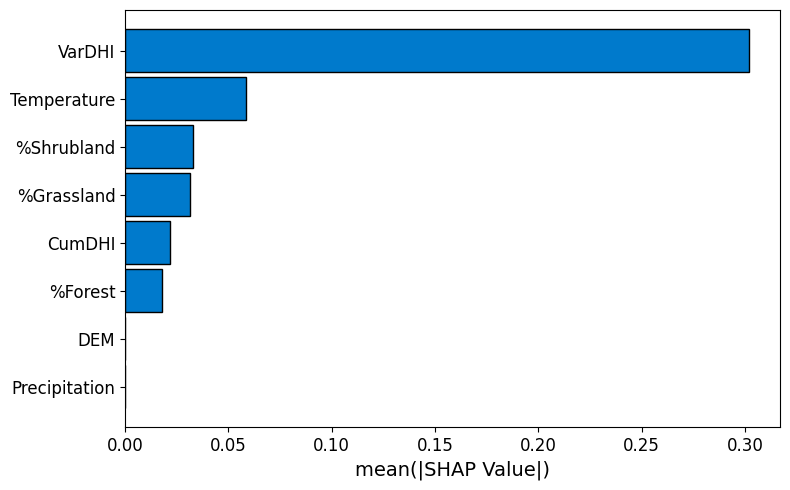

In [ ]:
import matplotlib.pyplot as plt
import pickle
import pandas as pd
import numpy as np

# Define custom feature name mapping
custom_feature_names_dict = {
    'CumDHI_4x4_average': 'CumDHI',
    'DEM_4x4_average': 'DEM',
    'Forest_percentage_4x4_average_reprojected': '%Forest',
    'Grassland_percentage_4x4_average_reprojected': '%Grassland',
    'precip_average': 'Precipitation',
    'Shrubland_percentage_4x4_average_reprojected': '%Shrubland',
    'tmax_average': 'Temperature',
    'VarDHI_4x4_average': 'VarDHI'
}

# Combine predictors
X = pd.concat([CumDHI_32x32, DEM, Forest_percentage, Grassland_percentage,
               Precipitation, Shrubland_percentage, Temperature, VarDHI_32x32], axis=1)

# Load SHAP values
with open('/content/drive/My Drive/SHAP_multipredictors/Guild/Woodland/4x4/SHAP/BGGN_8Predictors.pkl', 'rb') as f:
    shap_values = pickle.load(f)

# Compute mean absolute SHAP values
shap_values_mean = np.abs(shap_values).mean(axis=0)

# Create DataFrame for feature importance
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Mean SHAP Value': shap_values_mean
}).sort_values(by='Mean SHAP Value', ascending=False)

# Map original names to custom labels
custom_labels = [custom_feature_names_dict[feat] for feat in feature_importance['Feature']]

# Plot

plt.figure(figsize=(8, 5))  # Reduce height for tighter layout
bars = plt.barh(custom_labels, feature_importance['Mean SHAP Value'],
                height=0.9, color='#007acc', edgecolor='black')  # Thinner bars

# (Removed: loop adding value labels)

# Beautify plot
plt.gca().invert_yaxis()
plt.xlabel('mean(|SHAP Value|)', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.tight_layout()
plt.show()


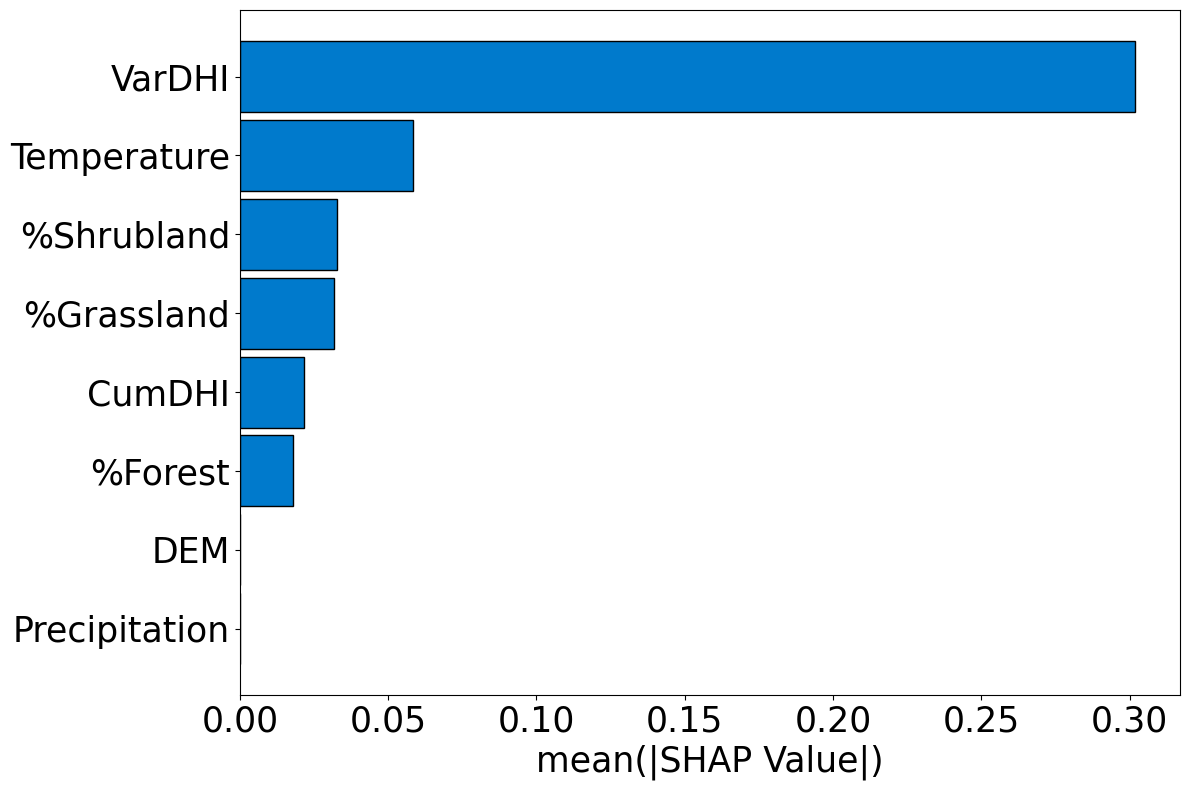

In [ ]:
import matplotlib.pyplot as plt
import pickle
import pandas as pd
import numpy as np

# Define custom feature name mapping
custom_feature_names_dict = {
    'CumDHI_4x4_average': 'CumDHI',
    'DEM_4x4_average': 'DEM',
    'Forest_percentage_4x4_average_reprojected': '%Forest',
    'Grassland_percentage_4x4_average_reprojected': '%Grassland',
    'precip_average': 'Precipitation',
    'Shrubland_percentage_4x4_average_reprojected': '%Shrubland',
    'tmax_average': 'Temperature',
    'VarDHI_4x4_average': 'VarDHI'
}

# Combine predictors
X = pd.concat([CumDHI_32x32, DEM, Forest_percentage, Grassland_percentage,
               Precipitation, Shrubland_percentage, Temperature, VarDHI_32x32], axis=1)

# Load SHAP values
with open('/content/drive/My Drive/SHAP_multipredictors/Guild/Woodland/4x4/SHAP/BGGN_8Predictors.pkl', 'rb') as f:
    shap_values = pickle.load(f)

# Compute mean absolute SHAP values
shap_values_mean = np.abs(shap_values).mean(axis=0)

# Create DataFrame for feature importance
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Mean SHAP Value': shap_values_mean
}).sort_values(by='Mean SHAP Value', ascending=False)

# Map original names to custom labels
custom_labels = [custom_feature_names_dict[feat] for feat in feature_importance['Feature']]

# Plot
plt.figure(figsize=(12, 8))
bars = plt.barh(custom_labels, feature_importance['Mean SHAP Value'],
                height=0.9, color='#007acc', edgecolor='black')

# Improve aesthetics
plt.gca().invert_yaxis()
plt.xlabel('mean(|SHAP Value|)', fontsize=25)
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)
#plt.title('Mean Absolute SHAP Values by Feature', fontsize=18)

plt.tight_layout()
plt.show()

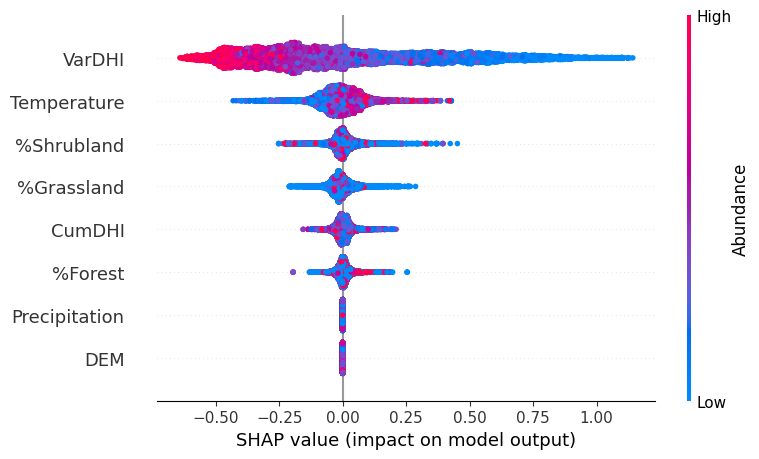

In [ ]:
# Apply custom labels in the same order as X.columns
custom_feature_names = [custom_feature_names_dict[col] for col in X.columns]

# Generate SHAP summary plot
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X, feature_names=custom_feature_names, show=False)

# Optional: Change colorbar label to 'Abundance'
plt.gcf().axes[-1].set_ylabel("Abundance", fontsize=12)

plt.tight_layout()
plt.show()

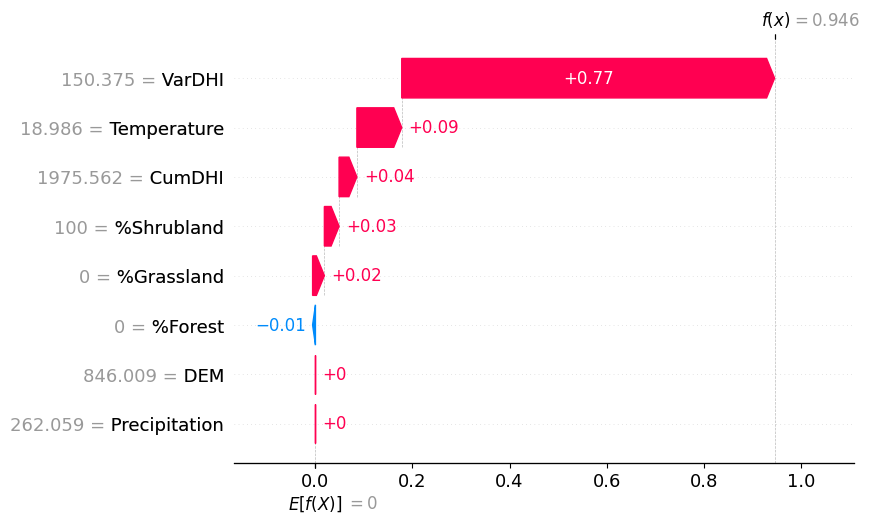

In [ ]:
import shap
# Apply custom labels in the same order as X.columns
custom_feature_names = [custom_feature_names_dict[col] for col in X.columns]

# Select the first point (index 0)
i = 9994  # or any index of interest

# Convert to SHAP Explanation object for a single sample
shap_values_single = shap.Explanation(
    values=shap_values[i],
    base_values=0,  # Optional: base value if available from your SHAP method, else use 0
    data=X.iloc[i],
    feature_names=custom_feature_names
)

# Plot the SHAP waterfall plot for that single prediction
shap.plots.waterfall(shap_values_single)

## Multiple species

In [3]:
# Define custom names (same order as X.columns)
custom_feature_names_dict = {
    'CumDHI_4x4_average': 'CumDHI',
    'DEM_4x4_average': 'DEM',
    'Forest_percentage_4x4_average_reprojected': '%Forest',
    'Grassland_percentage_4x4_average_reprojected': '%Grassland',
    'precip_average': 'Precipitation',
    'Shrubland_percentage_4x4_average_reprojected': '%Shrubland',
    'tmax_average': 'Temperature',
    'VarDHI_4x4_average': 'VarDHI'
}

species_list = ["AMRE", "HAWO", "PIWO", "WEWP"]#["HAFL","OSFL","RCKI","WETA","YRWA"]  # Forest
#species_list = ["BGGN","CAKI","EABL","PLVI","SAPH"] # Woodland
#species_list = ["GRSP", "LBCU", "MOBL", "UPSA", "WEME"]  # Grassland
#species_list = ["GRFL","LOSH","SATH","WEKI","YEWA"] # Shrubland
for species in species_list:
    # Load data
    data = pd.read_csv(f"/content/drive/My Drive/SHAP_multipredictors/Guild/Forest/4x4/Raster_extracted_4x4_Raster_extracted_Pred_ {species} .csv")
    y = data['Predicted']
    predictors = data.iloc[:,4:12]

    X = pd.concat([predictors], axis=1)
    #cumDHI = data.iloc[:, 7:16]
    #DEM = data.iloc[:, 16:25]
    #minDHI = data.iloc[:, 25:34]
    #varDHI = data.iloc[:, 34:43]

    #X = pd.concat([cumDHI], axis=1) # , DEM, minDHI, varDHI

    # Load SHAP values
    with open(f'/content/drive/My Drive/SHAP_multipredictors/Guild/Forest/4x4/SHAP/{species}_8Predictors.pkl', 'rb') as f:
        shap_values = pickle.load(f)

    # Generate SHAP summary plot
    # plt.figure(figsize=(12, 8))
    # shap.summary_plot(shap_values, X, show=False)  # `show=False` to avoid displaying in loop
    # plt.gcf().axes[-1].set_ylabel("CumDHI", fontsize=12)  # Change legend label to "Abundance"
    # plt.title(f'SHAP Summary Plot for {species}', fontsize=14)  # Add a title
    # Map original names to custom names
    custom_labels = [custom_feature_names_dict[feat] for feat in feature_importance['Feature']]

    plt.figure(figsize=(12, 8))
    shap.summary_plot(shap_values, X, feature_names=custom_feature_names, show=False)
    plt.gcf().axes[-1].set_ylabel("Abundance", fontsize=12)  # Change legend label to "Abundance"
    #plt.xlabel('Mean SHAP Value')
    #plt.ylabel('Feature')
    plt.title(f'SHAP Values (abundance) for {species}') # Dynamic title

    plt.savefig(f"/content/drive/My Drive/SHAP_multipredictors/Guild/Forest/4x4/SHAP/shap_beesworm_{species}.png", bbox_inches='tight')  # Save the plot

    plt.close()  # Close the figure to free memory


print("Plots generated and saved for all species.")

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/My Drive/SHAP_multipredictors/Guild/Forest/4x4/SHAP/AMRE_8Predictors.pkl'

Font change

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter
import pandas as pd
import pickle
import shap

# Define custom names (same order as X.columns)
custom_feature_names_dict = {
    'CumDHI_4x4_average': 'CumDHI',
    'DEM_4x4_average': 'DEM',
    'Forest_percentage_4x4_average_reprojected': '%Forest',
    'Grassland_percentage_4x4_average_reprojected': '%Grassland',
    'precip_average': 'Precipitation',
    'Shrubland_percentage_4x4_average_reprojected': '%Shrubland',
    'tmax_average': 'Temperature',
    'VarDHI_4x4_average': 'VarDHI'
}

species_list = ["BGGN", "CAKI", "EABL", "PLVI", "SAPH"]  # Woodland

for species in species_list:
    # Load data
    data = pd.read_csv(f"/content/drive/My Drive/SHAP_multipredictors/Guild/Woodland/4x4/Raster_extracted_4x4_Raster_extracted_Pred_ {species} .csv")
    y = data['Predicted']
    predictors = data.iloc[:, 4:12]
    X = pd.concat([predictors], axis=1)

    # Load SHAP values
    with open(f'/content/drive/My Drive/SHAP_multipredictors/Guild/Woodland/4x4/SHAP/{species}_8Predictors.pkl', 'rb') as f:
        shap_values = pickle.load(f)

    # Generate SHAP summary plot
    plt.figure(figsize=(12, 8))
    shap.summary_plot(shap_values, X, feature_names=[custom_feature_names_dict[col] for col in X.columns], show=False)

    # Update all font sizes to 18
    #plt.title(f'SHAP Values (abundance) for {species}', fontsize=18)
    ax = plt.gca()
    ax.set_xlabel("SHAP Value (feature importance)", fontsize=18)
    #ax.set_ylabel("Feature", fontsize=18)
    ax.tick_params(axis='both', labelsize=16)
    ax.xaxis.set_major_formatter(FormatStrFormatter('%.2f'))

    # Update color bar font size
    cbar = plt.gcf().axes[-1]
    cbar.set_ylabel("Abundance", fontsize=16)
    cbar.tick_params(labelsize=16)

    plt.tight_layout()
    plt.savefig(f"/content/drive/My Drive/SHAP_multipredictors/Guild/Woodland/4x4/SHAP/shap_beesworm_{species}.png", bbox_inches='tight')
    plt.close()

print("Plots generated and saved for all species.")

Plots generated and saved for all species.


Delete the cells below